<a href="https://colab.research.google.com/github/agungprayasa1-sketch/naive-bayes-sentimen-restoran/blob/main/NaiveBayes_Restoran.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Klasifikasi Sentimen Ulasan Restoran pada Google Maps Menggunakan Algoritma Naive Bayes
**Tugas Besar Kecerdasan Buatan — Telkom University, Tahun Akademik 2026/2027**

**Anggota:**
1. Qadlizaky Ermansyah — 101032400152
2. Bagus Suryansyah Dharmawinata — 101032400046
3. Muhammad Rahmad Dany — 101032400053
4. Agung Prayasa NR — 101032400182

**Dataset:** [Google Maps Restaurant Reviews (Kaggle)](https://www.kaggle.com/datasets/denizbilginn/google-maps-restaurant-reviews), menggunakan file `reviews.csv`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
import math
from collections import Counter

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, recall_score, f1_score)

In [ ]:
df = pd.read_csv('reviews.csv')

print("Ukuran data (baris, kolom):", df.shape)
print()
print("Jumlah ulasan per bintang:")
print(df['rating'].value_counts().sort_index())
df.head()

Ukuran data (baris, kolom): (1100, 6)

Jumlah ulasan per bintang:
rating
1     80
2     72
3    172
4    316
5    460
Name: count, dtype: int64


,business_name,author_name,text,photo,rating,rating_category
0,Haci'nin Yeri - Yigit Lokantasi,Gulsum Akar,We went to Marmaris with my wife for a holiday...,dataset/taste/hacinin_yeri_gulsum_akar.png,5,taste
1,Haci'nin Yeri - Yigit Lokantasi,Oguzhan Cetin,During my holiday in Marmaris we ate here to f...,dataset/menu/hacinin_yeri_oguzhan_cetin.png,4,menu
2,Haci'nin Yeri - Yigit Lokantasi,Yasin Kuyu,Prices are very affordable. The menu in the ph...,dataset/outdoor_atmosphere/hacinin_yeri_yasin_...,3,outdoor_atmosphere
3,Haci'nin Yeri - Yigit Lokantasi,Orhan Kapu,Turkey's cheapest artisan restaurant and its f...,dataset/indoor_atmosphere/hacinin_yeri_orhan_k...,5,indoor_atmosphere
4,Haci'nin Yeri - Yigit Lokantasi,Ozgur Sati,I don't know what you will look for in terms o...,dataset/menu/hacinin_yeri_ozgur_sati.png,3,menu


In [ ]:
data = df[df['rating'] != 3].copy()
data['sentimen'] = np.where(data['rating'] >= 4, 'positif', 'negatif')

print("Jumlah ulasan sebelum:", len(df))
print("Jumlah ulasan sesudah:", len(data))
print("Ulasan yang teksnya kosong:", data['text'].isnull().sum())
print()
print(data['sentimen'].value_counts())

Jumlah ulasan sebelum: 1100
Jumlah ulasan sesudah: 928
Ulasan yang teksnya kosong: 0

sentimen
positif    776
negatif    152
Name: count, dtype: int64


In [ ]:
print("Contoh ulasan POSITIF:")
print(data[data['sentimen'] == 'positif']['text'].iloc[0])
print()
print("Contoh ulasan NEGATIF:")
print(data[data['sentimen'] == 'negatif']['text'].iloc[0])

Contoh ulasan POSITIF:
We went to Marmaris with my wife for a holiday. We chose this restaurant as a place for dinner based on the reviews and because we wanted juicy food. When we first went there was a serious queue. You proceed by taking the food you want in the form of an open buffet. Both vegetable dishes and meat dishes were plentiful. There was also dessert for those who wanted it. After you get what you want you pay at the cashier. They don't go through cards they work in cash. There was a lot of food variety. And the food prices were unbelievably cheap. We paid only 84 TL for all the meals here. It included buttermilk and bread. But unfortunately I can't say it's too clean as a place..

Contoh ulasan NEGATIF:
Flavor : It has nothing but dough taste. Labor : Not befitting a touristic place. Service : There was no wet wipes and napkins on the table, but there was no sympathetic family to say. This service and this taste were not available at this price.


In [ ]:
kata_negasi = {'not', 'no', 'never', 'nothing', 'none', 'nor', 'cannot', 'without'}
stopwords = set(ENGLISH_STOP_WORDS) - kata_negasi

print("Jumlah stopword:", len(stopwords))

Jumlah stopword: 310


In [ ]:
def bersihkan(teks):
    teks = teks.lower()                                    # 1. huruf kecil semua
    teks = teks.replace("’", "'").replace("n't", " not")   #    don't -> do not
    teks = re.sub(r'[^a-z]', ' ', teks)                    # 2. selain huruf a-z diganti spasi
    daftar_kata = teks.split()                             # 3. pecah jadi daftar kata

    hasil = []                                             # 4. buang stopword
    for k in daftar_kata:
        if k not in stopwords and len(k) > 1:
            hasil.append(k)
    return hasil

In [ ]:
contoh = data[data['sentimen'] == 'negatif']['text'].iloc[0]

print("SEBELUM:")
print(contoh)
print()
print("SESUDAH:")
print(bersihkan(contoh))

SEBELUM:
Flavor : It has nothing but dough taste. Labor : Not befitting a touristic place. Service : There was no wet wipes and napkins on the table, but there was no sympathetic family to say. This service and this taste were not available at this price.

SESUDAH:
['flavor', 'nothing', 'dough', 'taste', 'labor', 'not', 'befitting', 'touristic', 'place', 'service', 'no', 'wet', 'wipes', 'napkins', 'table', 'no', 'sympathetic', 'family', 'say', 'service', 'taste', 'not', 'available', 'price']


In [ ]:
data['kata'] = data['text'].apply(bersihkan)

print("Ulasan yang jadi kosong setelah dibersihkan:", (data['kata'].apply(len) == 0).sum())
data[['text', 'kata', 'sentimen']].head()

Ulasan yang jadi kosong setelah dibersihkan: 0


,text,kata,sentimen
0,We went to Marmaris with my wife for a holiday...,"[went, marmaris, wife, holiday, chose, restaur...",positif
1,During my holiday in Marmaris we ate here to f...,"[holiday, marmaris, ate, fit, food, really, go...",positif
3,Turkey's cheapest artisan restaurant and its f...,"[turkey, cheapest, artisan, restaurant, food, ...",positif
5,Generally good.,"[generally, good]",positif
6,What you see is 125 TL in total. It's a pretty...,"[tl, total, pretty, convenient, place, say, ar...",positif


In [ ]:
X = data['kata'].tolist()
y = data['sentimen'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Data latih:", len(X_train), "ulasan ->", dict(Counter(y_train)))
print("Data uji  :", len(X_test), "ulasan ->", dict(Counter(y_test)))

Data latih: 742 ulasan -> {'positif': 620, 'negatif': 122}
Data uji  : 186 ulasan -> {'positif': 156, 'negatif': 30}


In [ ]:
daftar_kelas = ['negatif', 'positif']

def latih_nb(X_latih, y_latih):
    # 1. Peluang awal (prior)
    jumlah_ulasan = Counter(y_latih)
    prior = {}
    for kelas in daftar_kelas:
        prior[kelas] = jumlah_ulasan[kelas] / len(y_latih)

    # 2. Hitung kemunculan kata di tiap kelas
    jumlah_kata = {'negatif': Counter(), 'positif': Counter()}
    for i in range(len(X_latih)):
        jumlah_kata[y_latih[i]].update(X_latih[i])

    # 3. Kosakata dan total kata
    kosakata = set()
    for ulasan in X_latih:
        kosakata.update(ulasan)
    total_kata = {}
    for kelas in daftar_kelas:
        total_kata[kelas] = sum(jumlah_kata[kelas].values())

    return prior, jumlah_kata, kosakata, total_kata

In [ ]:
model_nb = latih_nb(X_train, y_train)
prior, jumlah_kata, kosakata, total_kata = model_nb

for kelas in daftar_kelas:
    print(f"Peluang awal {kelas}: {prior[kelas]:.3f}")
print()
print("Jumlah kata unik (kosakata):", len(kosakata))
for kelas in daftar_kelas:
    print(f"Total kata di ulasan {kelas}: {total_kata[kelas]}")

Peluang awal negatif: 0.164
Peluang awal positif: 0.836

Jumlah kata unik (kosakata): 1672
Total kata di ulasan negatif: 1302
Total kata di ulasan positif: 5963


In [ ]:
for kelas in daftar_kelas:
    print(f"10 kata paling sering di ulasan {kelas}:")
    for kata, jumlah in jumlah_kata[kelas].most_common(10):
        print(f"   {kata:12s} {jumlah} kali")
    print()

10 kata paling sering di ulasan negatif:
   not          80 kali
   service      24 kali
   bad          22 kali
   taste        20 kali
   did          20 kali
   good         17 kali
   place        15 kali
   food         14 kali
   prices       13 kali
   came         13 kali

10 kata paling sering di ulasan positif:
   good         172 kali
   place        142 kali
   delicious    140 kali
   not          118 kali
   nice         111 kali
   taste        92 kali
   service      79 kali
   prices       77 kali
   food         77 kali
   great        61 kali



In [ ]:
def peluang_kata(kata, kelas):
    return (jumlah_kata[kelas][kata] + 1) / (total_kata[kelas] + len(kosakata))

In [ ]:
for kata in ['delicious', 'nice', 'great', 'good', 'food', 'service', 'not', 'did', 'bad']:
    p_neg = peluang_kata(kata, 'negatif')
    p_pos = peluang_kata(kata, 'positif')

    if p_pos > p_neg:
        condong = f"positif ({p_pos / p_neg:.1f}x)"
    else:
        condong = f"negatif ({p_neg / p_pos:.1f}x)"

    print(f"{kata:10s}  negatif: {p_neg:.5f}   positif: {p_pos:.5f}   -> condong ke {condong}")

delicious   negatif: 0.00168   positif: 0.01847   -> condong ke positif (11.0x)
nice        negatif: 0.00303   positif: 0.01467   -> condong ke positif (4.8x)
great       negatif: 0.00067   positif: 0.00812   -> condong ke positif (12.1x)
good        negatif: 0.00605   positif: 0.02266   -> condong ke positif (3.7x)
food        negatif: 0.00504   positif: 0.01022   -> condong ke positif (2.0x)
service     negatif: 0.00841   positif: 0.01048   -> condong ke positif (1.2x)
not         negatif: 0.02724   positif: 0.01559   -> condong ke negatif (1.7x)
did         negatif: 0.00706   positif: 0.00236   -> condong ke negatif (3.0x)
bad         negatif: 0.00773   positif: 0.00223   -> condong ke negatif (3.5x)


In [ ]:
def tebak_nb(ulasan, model, prior_seimbang=False):
    prior, jumlah_kata, kosakata, total_kata = model
    skor = {}
    for kelas in daftar_kelas:
        # 1. Titik awal: sesuai data, atau 50:50
        if prior_seimbang:
            skor[kelas] = math.log(0.5)
        else:
            skor[kelas] = math.log(prior[kelas])

        # 2. Tambahkan log peluang setiap kata (Laplace smoothing)
        for kata in ulasan:
            if kata in kosakata:
                p = (jumlah_kata[kelas][kata] + 1) / (total_kata[kelas] + len(kosakata))
                skor[kelas] += math.log(p)

    # 3. Pilih kelas dengan skor tertinggi
    if skor['positif'] > skor['negatif']:
        return 'positif'
    else:
        return 'negatif'

In [ ]:
print(0.01 ** 100)
print(0.01 ** 200)

1.000000000000002e-200
0.0


In [ ]:
nomor = 0
ulasan = X_test[nomor]

print("Kata-kata ulasan:", ulasan)
print("Label asli      :", y_test[nomor])
print()

skor_neg = math.log(prior['negatif'])
skor_pos = math.log(prior['positif'])
print(f"{'(peluang awal)':15s} neg: {skor_neg:7.3f}   pos: {skor_pos:7.3f}")

for kata in ulasan:
    if kata not in kosakata:
        print(f"{kata:15s} (tidak ada di data latih, dilewati)")
        continue
    log_neg = math.log(peluang_kata(kata, 'negatif'))
    log_pos = math.log(peluang_kata(kata, 'positif'))
    skor_neg += log_neg
    skor_pos += log_pos
    print(f"{kata:15s} neg: {log_neg:7.3f}   pos: {log_pos:7.3f}")

print()
print(f"Total skor negatif: {skor_neg:.3f}")
print(f"Total skor positif: {skor_pos:.3f}")
print("Prediksi lewat fungsi tebak_nb:", tebak_nb(ulasan, model_nb))

Kata-kata ulasan: ['food', 'came', 'table', 'high', 'quality', 'delicious', 'recommend']
Label asli      : positif

(peluang awal)  neg:  -1.805   pos:  -0.180
food            neg:  -5.290   pos:  -4.584
came            neg:  -5.359   pos:  -5.645
table           neg:  -6.388   pos:  -6.861
high            neg:  -6.206   pos:  -5.945
quality         neg:  -6.388   pos:  -5.645
delicious       neg:  -6.388   pos:  -3.992
recommend       neg:  -6.052   pos:  -4.830

Total skor negatif: -43.876
Total skor positif: -37.680
Prediksi lewat fungsi tebak_nb: positif


In [ ]:
prediksi_awal = []
for ulasan in X_test:
    prediksi_awal.append(tebak_nb(ulasan, model_nb))
prediksi_awal = np.array(prediksi_awal)

baseline = np.mean(y_test == 'positif')
negatif_asli = (y_test == 'negatif')

print("Akurasi     :", round(np.mean(prediksi_awal == y_test) * 100, 2), "%")
print("Baseline    :", round(baseline * 100, 2), "%  (selalu menebak positif)")
print("Ulasan negatif yang dikenali:", np.sum(prediksi_awal[negatif_asli] == 'negatif'), "dari", np.sum(negatif_asli))

Akurasi     : 87.1 %
Baseline    : 83.87 %  (selalu menebak positif)
Ulasan negatif yang dikenali: 6 dari 30


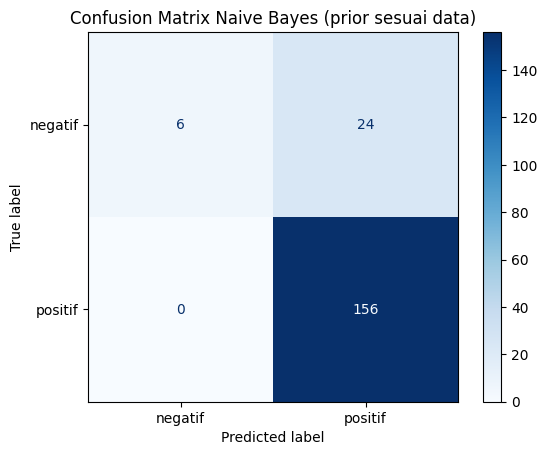

              precision    recall  f1-score   support

     negatif       1.00      0.20      0.33        30
     positif       0.87      1.00      0.93       156

    accuracy                           0.87       186
   macro avg       0.93      0.60      0.63       186
weighted avg       0.89      0.87      0.83       186



In [ ]:
cm_awal = confusion_matrix(y_test, prediksi_awal, labels=daftar_kelas)
ConfusionMatrixDisplay(cm_awal, display_labels=daftar_kelas).plot(cmap='Blues')
plt.title('Confusion Matrix Naive Bayes (prior sesuai data)')
plt.show()

print(classification_report(y_test, prediksi_awal, labels=daftar_kelas))

In [ ]:
salah = np.where((y_test == 'negatif') & (prediksi_awal == 'positif'))[0]
print("Ulasan negatif yang ditebak positif:", len(salah))
print()

for idx in salah[:3]:
    print(f"Ulasan uji ke-{idx}:")
    print("   ", ' '.join(X_test[idx]))
    print()

Ulasan negatif yang ditebak positif: 24

Ulasan uji ke-1:
    mussels half kokorec tl place smells like toilet

Ulasan uji ke-7:
    place nice employees good food delicious human pilfering extra charge caused point

Ulasan uji ke-15:
    breakfast morning usually crowded weekends service delayed meals not bad



In [ ]:
vectorizer = CountVectorizer(analyzer=lambda kata: kata)
X_train_angka = vectorizer.fit_transform(X_train)
X_test_angka  = vectorizer.transform(X_test)

model_sklearn = MultinomialNB(alpha=1.0)
model_sklearn.fit(X_train_angka, y_train)
prediksi_sklearn = model_sklearn.predict(X_test_angka)

print("Ukuran tabel data latih:", X_train_angka.shape)
print("Kosakata sklearn:", len(vectorizer.vocabulary_), "| kosakata buatan sendiri:", len(kosakata))
print("Tebakan yang sama:", np.sum(prediksi_awal == prediksi_sklearn), "dari", len(y_test), "ulasan")

Ukuran tabel data latih: (742, 1672)
Kosakata sklearn: 1672 | kosakata buatan sendiri: 1672
Tebakan yang sama: 186 dari 186 ulasan


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def evaluasi_cv(prior_seimbang):
    daftar_recall = []
    daftar_f1 = []
    for idx_latih, idx_val in skf.split(X_train, y_train):
        # 1. Pisahkan data latih dan validasi untuk try-out ini
        X_lat = [X_train[i] for i in idx_latih]
        y_lat = y_train[idx_latih]
        X_val = [X_train[i] for i in idx_val]
        y_val = y_train[idx_val]

        # 2. Latih Naive Bayes dari data latih try-out ini saja
        model_fold = latih_nb(X_lat, y_lat)

        # 3. Tebak semua ulasan validasi
        pred = []
        for ulasan in X_val:
            pred.append(tebak_nb(ulasan, model_fold, prior_seimbang))

        # 4. Simpan nilainya
        daftar_recall.append(recall_score(y_val, pred, pos_label='negatif'))
        daftar_f1.append(f1_score(y_val, pred, average='macro'))

    return np.mean(daftar_recall), np.mean(daftar_f1)

In [ ]:
for nama, seimbang in [('Prior sesuai data', False), ('Prior seimbang', True)]:
    recall_neg, f1_macro = evaluasi_cv(seimbang)
    print(f"{nama:18s} ->  recall negatif: {recall_neg*100:5.1f}%   F1 macro: {f1_macro:.3f}")

Prior sesuai data  ->  recall negatif:  25.2%   F1 macro: 0.643
Prior seimbang     ->  recall negatif:  49.0%   F1 macro: 0.742


Akurasi akhir: 88.17 %



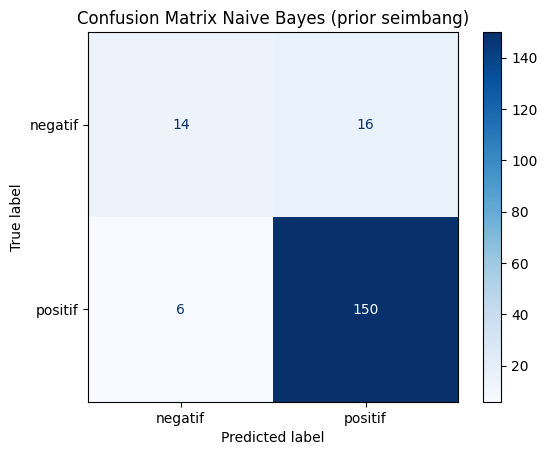

              precision    recall  f1-score   support

     negatif       0.70      0.47      0.56        30
     positif       0.90      0.96      0.93       156

    accuracy                           0.88       186
   macro avg       0.80      0.71      0.75       186
weighted avg       0.87      0.88      0.87       186



In [ ]:
prediksi_final = []
for ulasan in X_test:
    prediksi_final.append(tebak_nb(ulasan, model_nb, prior_seimbang=True))
prediksi_final = np.array(prediksi_final)

print("Akurasi akhir:", round(np.mean(prediksi_final == y_test) * 100, 2), "%")
print()

cm_final = confusion_matrix(y_test, prediksi_final, labels=daftar_kelas)
ConfusionMatrixDisplay(cm_final, display_labels=daftar_kelas).plot(cmap='Blues')
plt.title('Confusion Matrix Naive Bayes (prior seimbang)')
plt.show()

print(classification_report(y_test, prediksi_final, labels=daftar_kelas))

In [ ]:
model_sklearn_final = MultinomialNB(alpha=1.0, fit_prior=False)
model_sklearn_final.fit(X_train_angka, y_train)
prediksi_sklearn_final = model_sklearn_final.predict(X_test_angka)

print("Tebakan yang sama dengan sklearn:", np.sum(prediksi_final == prediksi_sklearn_final), "dari", len(y_test), "ulasan")

Tebakan yang sama dengan sklearn: 186 dari 186 ulasan
